# Contoh

 PIPELINE SEGMENTASI BARIS TULISAN TANGAN
 Grayscale -> Blur -> Threshold -> Line Removal -> Segmentasi
[LOAD] Gambar berhasil dibaca: 2479x2102 piksel
[GRAY] Shape sebelum: (2102, 2479, 3)  -->  Shape setelah: (2102, 2479)
[BLUR] Gaussian Blur kernel 3x3 diterapkan
[BINARIZE] Piksel foreground (putih): 161173 (3.1%)
[LINE REMOVAL - Morph] Piksel garis dihapus (morph): 7046
[LINE REMOVAL - Hough] Garis tipis dihapus (hough): 136 segmen
[PROJECTION] Savitzky-Golay filter window=51 diterapkan
  Max proyeksi: 413.2  |  Mean non-zero: 73.3
[SEGMENT] Threshold proyeksi: 41.32
[SEGMENT] Kandidat segmen: 9 segmen
[SEGMENT] Padding adaptif: atas=18px  bawah=24px
[SEGMENT] Total baris terdeteksi: 9

 HASIL AKHIR: 9 baris tulisan terdeteksi

[VIS] Menampilkan visualisasi per step...
[INPUT VIS] Ukuran: 2479x2102px  |  R: 233.9+-30.2  G: 233.9+-30.2  B: 233.9+-30.2


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10868\3264252158.py:269: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


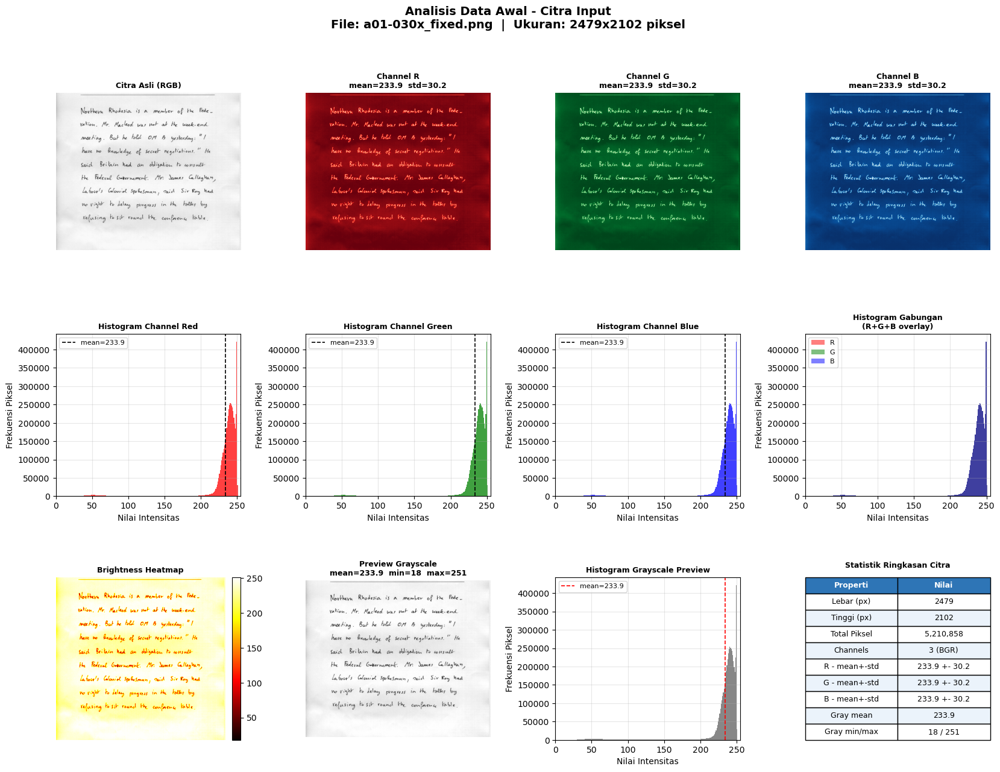

[VIS] Input Overview ditampilkan


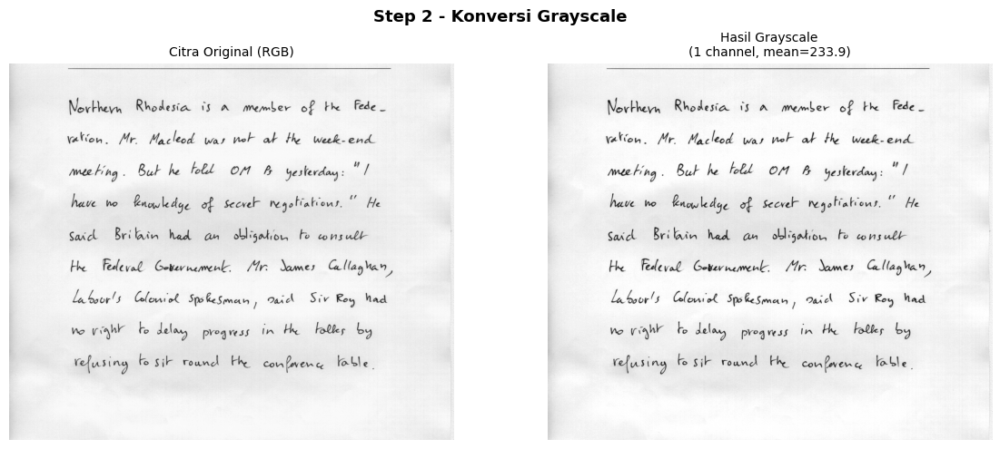

[VIS] Step 2 Grayscale ditampilkan


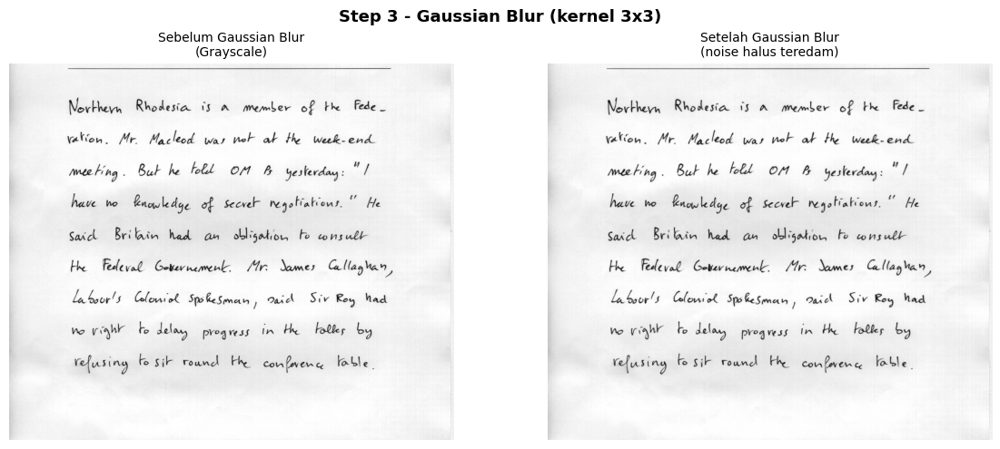

[VIS] Step 3 Gaussian Blur ditampilkan


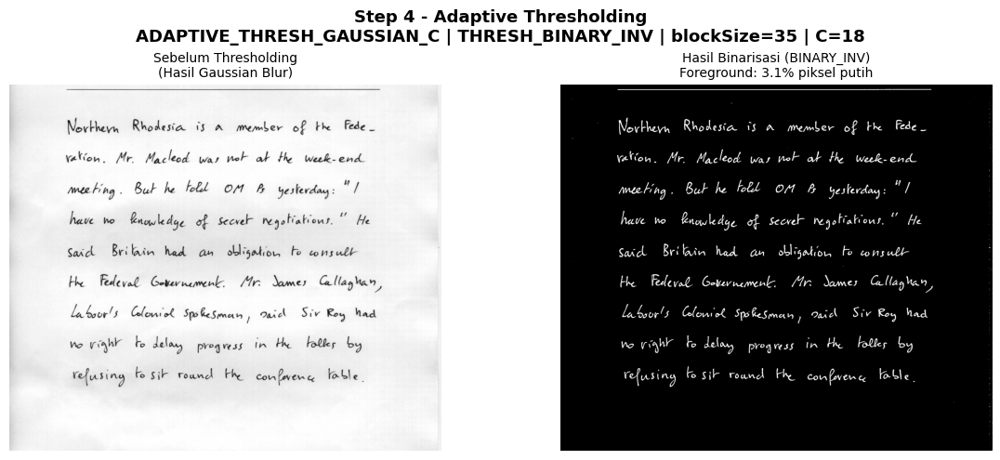

[VIS] Step 4 Adaptive Threshold ditampilkan


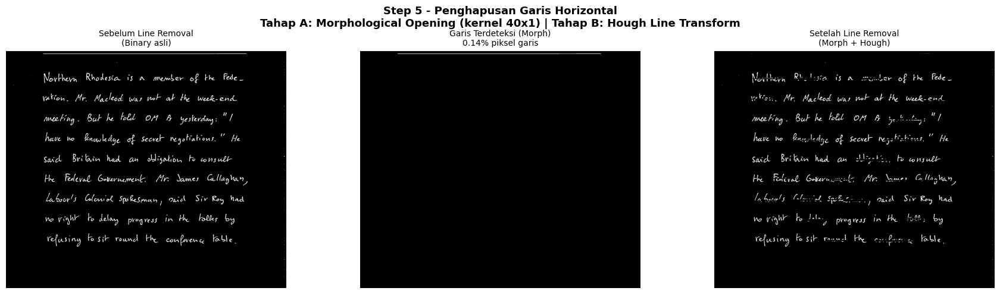

[VIS] Step 5 Line Removal ditampilkan


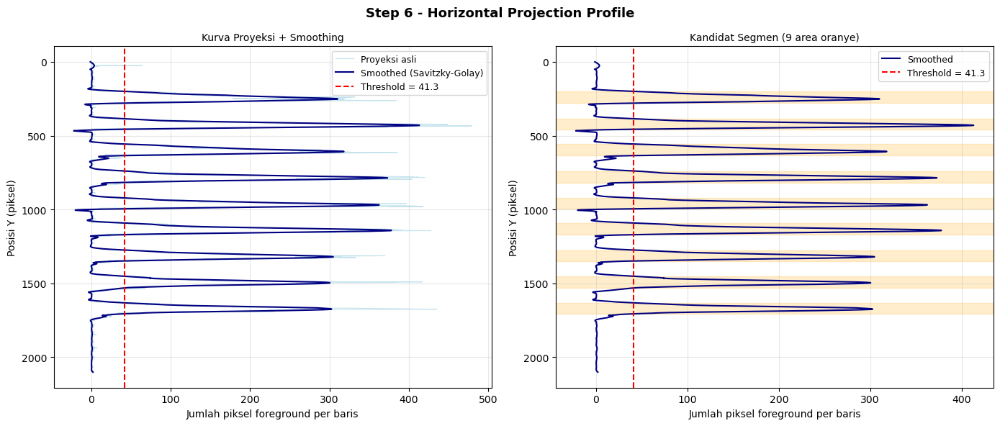

[VIS] Step 6 Projection Profile ditampilkan


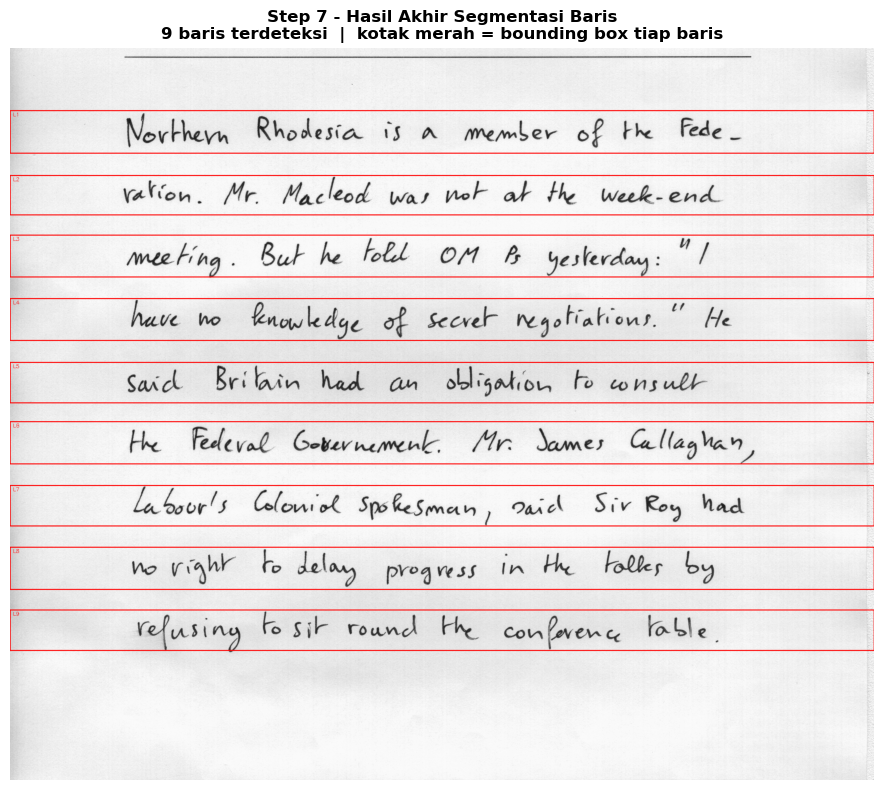

[VIS] Step 7 Hasil Segmentasi ditampilkan


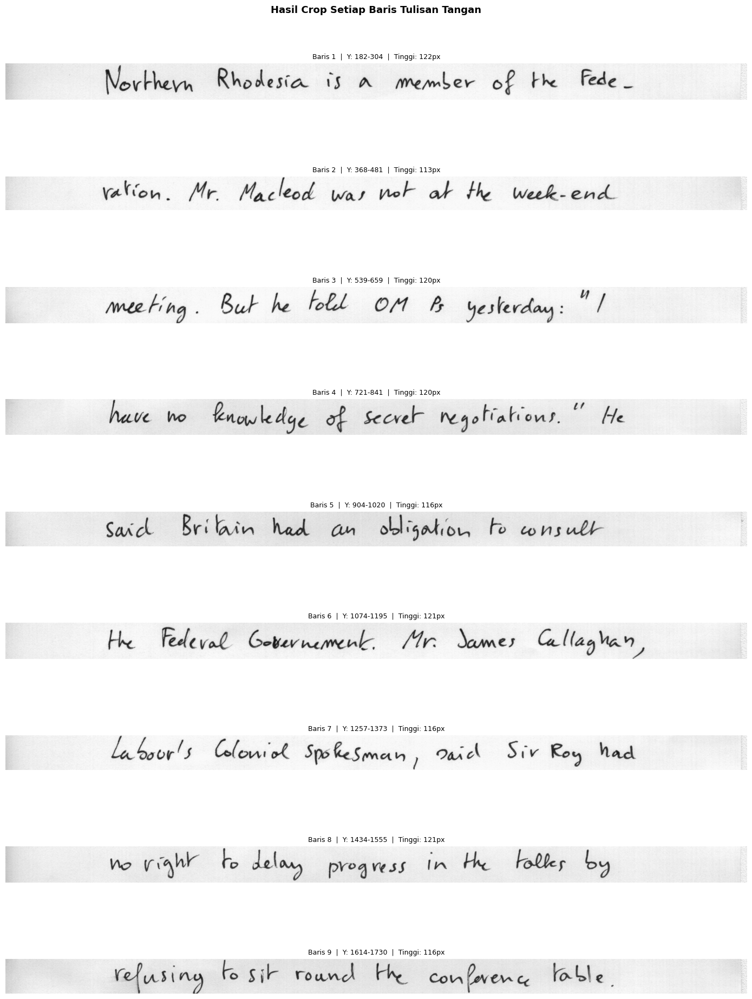

[VIS] Crops (9 baris) ditampilkan
[VIS] Semua visualisasi selesai.


In [2]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import signal
import os
from tqdm import tqdm



# STEP 1: LOAD GAMBAR

def load_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")
    H, W = img.shape[:2]
    print(f"[LOAD] Gambar berhasil dibaca: {W}x{H} piksel")
    return img



# STEP 2: KONVERSI GRAYSCALE

def convert_to_grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print(f"[GRAY] Shape sebelum: {img.shape}  -->  Shape setelah: {gray.shape}")
    return gray



# STEP 3: GAUSSIAN BLUR (DENOISING)

def apply_gaussian_blur(gray):
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    print(f"[BLUR] Gaussian Blur kernel 3x3 diterapkan")
    return blurred



# STEP 4: ADAPTIVE THRESHOLDING (BINARISASI)

def adaptive_threshold(blurred):
    binary = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=35,
        C=18
    )
    white_pixels = np.sum(binary == 255)
    total_pixels = binary.size
    print(f"[BINARIZE] Piksel foreground (putih): {white_pixels} ({100*white_pixels/total_pixels:.1f}%)")
    return binary



# STEP 5: PENGHAPUSAN GARIS HORIZONTAL

def remove_horizontal_lines(binary):
    result = binary.copy()

    # -- Tahap A: Morphological --
    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (40, 1))
    detected_morph = cv2.morphologyEx(result, cv2.MORPH_OPEN, kernel_h, iterations=2)
    result = cv2.subtract(result, detected_morph)
    morph_pixels = np.sum(detected_morph == 255)
    print(f"[LINE REMOVAL - Morph] Piksel garis dihapus (morph): {morph_pixels}")

    # -- Tahap B: Hough --
    lines = cv2.HoughLinesP(result, 1, np.pi / 180, 80,
                             minLineLength=150, maxLineGap=20)
    removed_hough = 0
    if lines is not None:
        for l in lines:
            x1, y1, x2, y2 = l[0]
            angle = abs(np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi)
            if angle < 8 or angle > 172:
                cv2.line(result, (x1, y1), (x2, y2), 0, 3)
                removed_hough += 1
    print(f"[LINE REMOVAL - Hough] Garis tipis dihapus (hough): {removed_hough} segmen")

    return result, detected_morph, removed_hough



# STEP 6: PROYEKSI HORIZONTAL (HORIZONTAL PROJECTION PROFILE)

def horizontal_projection(binary_clean, H, W):
    hist = cv2.reduce(binary_clean, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32F).flatten() / 255.0

    window = min(51, len(hist) if len(hist) % 2 == 1 else len(hist) - 1)
    if window >= 3:
        hist_smooth = signal.savgol_filter(hist, window, 3)
    else:
        hist_smooth = hist.copy()

    print(f"[PROJECTION] Savitzky-Golay filter window={window} diterapkan")
    print(f"  Max proyeksi: {hist_smooth.max():.1f}  |  Mean non-zero: {hist_smooth[hist_smooth>0].mean():.1f}")
    return hist, hist_smooth



# STEP 7: DETEKSI DAN SEGMENTASI BARIS

def detect_and_segment_lines(binary_clean, hist_smooth, H, W):
    nonzero = hist_smooth[hist_smooth > 0]
    if len(nonzero) > 0:
        threshold = max(np.mean(nonzero) * 0.3, np.max(hist_smooth) * 0.1)
    else:
        threshold = np.max(hist_smooth) * 0.1
    print(f"[SEGMENT] Threshold proyeksi: {threshold:.2f}")

    # -- Segmentasi awal --
    raw_segments = []
    in_line = False
    start = 0
    for i, val in enumerate(hist_smooth):
        if val > threshold and not in_line:
            start = i
            in_line = True
        elif val <= threshold and in_line:
            raw_segments.append((start, i))
            in_line = False
    if in_line:
        raw_segments.append((start, len(hist_smooth)))
    print(f"[SEGMENT] Kandidat segmen: {len(raw_segments)} segmen")

    # -- Adaptive padding --
    if raw_segments:
        avg_h = np.mean([y2 - y1 for y1, y2 in raw_segments])
        pad_top = max(int(avg_h * 0.2), 18)
        pad_bot = max(int(avg_h * 0.32), 22)
    else:
        pad_top, pad_bot = 18, 22
    print(f"[SEGMENT] Padding adaptif: atas={pad_top}px  bawah={pad_bot}px")

    final = []
    for i, (y1, y2) in enumerate(raw_segments):
        y1p = y1 - pad_top
        y2p = y2 + pad_bot
        if i > 0:
            y1p = max(y1p, raw_segments[i - 1][1])
        if i < len(raw_segments) - 1:
            y2p = min(y2p, raw_segments[i + 1][0])
        final.append((max(0, y1p), min(H, y2p)))

    print(f"[SEGMENT] Total baris terdeteksi: {len(final)}")
    return final, threshold, raw_segments



# VISUALISASI PER STEP (TAMPIL SAJA, TIDAK DISIMPAN)


def _show(fig, label):
    plt.show()
    plt.close(fig)
    print(f"[VIS] {label} ditampilkan")


def vis_input_overview(img, image_path):
    H, W = img.shape[:2]
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    b, g, r = cv2.split(img)
    mean_r, std_r = r.mean(), r.std()
    mean_g, std_g = g.mean(), g.std()
    mean_b, std_b = b.mean(), b.std()
    gray_preview = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    print(f"[INPUT VIS] Ukuran: {W}x{H}px  |  "
          f"R: {mean_r:.1f}+-{std_r:.1f}  "
          f"G: {mean_g:.1f}+-{std_g:.1f}  "
          f"B: {mean_b:.1f}+-{std_b:.1f}")

    fig = plt.figure(figsize=(20, 14))
    fig.suptitle(
        f"Analisis Data Awal - Citra Input\n"
        f"File: {os.path.basename(image_path)}  |  Ukuran: {W}x{H} piksel",
        fontsize=14, fontweight='bold', y=0.98
    )
    gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.5, wspace=0.35)

    ax_rgb = fig.add_subplot(gs[0, 0])
    ax_rgb.imshow(img_rgb)
    ax_rgb.set_title("Citra Asli (RGB)", fontsize=9, fontweight='bold')
    ax_rgb.axis('off')

    for col, (ch, cmap, title) in enumerate([
        (r, 'Reds',   f"Channel R\nmean={mean_r:.1f}  std={std_r:.1f}"),
        (g, 'Greens', f"Channel G\nmean={mean_g:.1f}  std={std_g:.1f}"),
        (b, 'Blues',  f"Channel B\nmean={mean_b:.1f}  std={std_b:.1f}"),
    ], start=1):
        ax = fig.add_subplot(gs[0, col])
        ax.imshow(ch, cmap=cmap)
        ax.set_title(title, fontsize=9, fontweight='bold')
        ax.axis('off')

    for col, (color, ch, label) in enumerate([
        ('r', r, 'Red'), ('g', g, 'Green'), ('b', b, 'Blue')
    ]):
        ax = fig.add_subplot(gs[1, col])
        ax.hist(ch.ravel(), bins=256, range=(0, 255), color=color, alpha=0.75)
        ax.axvline(ch.mean(), color='black', linestyle='--', linewidth=1.2,
                   label=f'mean={ch.mean():.1f}')
        ax.set_xlim(0, 255)
        ax.set_xlabel("Nilai Intensitas"); ax.set_ylabel("Frekuensi Piksel")
        ax.set_title(f"Histogram Channel {label}", fontsize=9, fontweight='bold')
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    ax_all = fig.add_subplot(gs[1, 3])
    ax_all.hist(r.ravel(), bins=256, range=(0,255), color='red',   alpha=0.5, label='R')
    ax_all.hist(g.ravel(), bins=256, range=(0,255), color='green', alpha=0.5, label='G')
    ax_all.hist(b.ravel(), bins=256, range=(0,255), color='blue',  alpha=0.5, label='B')
    ax_all.set_xlim(0, 255)
    ax_all.set_xlabel("Nilai Intensitas"); ax_all.set_ylabel("Frekuensi Piksel")
    ax_all.set_title("Histogram Gabungan\n(R+G+B overlay)", fontsize=9, fontweight='bold')
    ax_all.legend(fontsize=8); ax_all.grid(True, alpha=0.3)

    ax_heat = fig.add_subplot(gs[2, 0])
    hm = ax_heat.imshow(gray_preview, cmap='hot', aspect='auto')
    plt.colorbar(hm, ax=ax_heat, fraction=0.046, pad=0.04)
    ax_heat.set_title("Brightness Heatmap", fontsize=9, fontweight='bold')
    ax_heat.axis('off')

    ax_gray = fig.add_subplot(gs[2, 1])
    ax_gray.imshow(gray_preview, cmap='gray')
    ax_gray.set_title(f"Preview Grayscale\nmean={gray_preview.mean():.1f}  "
                      f"min={gray_preview.min()}  max={gray_preview.max()}",
                      fontsize=9, fontweight='bold')
    ax_gray.axis('off')

    ax_gh = fig.add_subplot(gs[2, 2])
    ax_gh.hist(gray_preview.ravel(), bins=256, range=(0,255), color='dimgray', alpha=0.8)
    ax_gh.axvline(gray_preview.mean(), color='red', linestyle='--', linewidth=1.2,
                  label=f'mean={gray_preview.mean():.1f}')
    ax_gh.set_xlim(0, 255)
    ax_gh.set_xlabel("Nilai Intensitas"); ax_gh.set_ylabel("Frekuensi Piksel")
    ax_gh.set_title("Histogram Grayscale Preview", fontsize=9, fontweight='bold')
    ax_gh.legend(fontsize=8); ax_gh.grid(True, alpha=0.3)

    ax_tbl = fig.add_subplot(gs[2, 3])
    ax_tbl.axis('off')
    stats_data = [
        ["Properti",      "Nilai"],
        ["Lebar (px)",    str(W)],
        ["Tinggi (px)",   str(H)],
        ["Total Piksel",  f"{W*H:,}"],
        ["Channels",      "3 (BGR)"],
        ["R - mean+-std", f"{mean_r:.1f} +- {std_r:.1f}"],
        ["G - mean+-std", f"{mean_g:.1f} +- {std_g:.1f}"],
        ["B - mean+-std", f"{mean_b:.1f} +- {std_b:.1f}"],
        ["Gray mean",     f"{gray_preview.mean():.1f}"],
        ["Gray min/max",  f"{gray_preview.min()} / {gray_preview.max()}"],
    ]
    tbl = ax_tbl.table(cellText=stats_data[1:], colLabels=stats_data[0],
                       cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_facecolor('#2E75B6')
            cell.set_text_props(color='white', fontweight='bold')
        elif row % 2 == 0:
            cell.set_facecolor('#EBF3FB')
    ax_tbl.set_title("Statistik Ringkasan Citra", fontsize=9, fontweight='bold', pad=12)

    plt.tight_layout()
    _show(fig, "Input Overview")


def vis_step2_grayscale(img, gray):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 2 - Konversi Grayscale", fontsize=13, fontweight='bold')
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Citra Original (RGB)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(gray, cmap='gray')
    axes[1].set_title(f"Hasil Grayscale\n(1 channel, mean={gray.mean():.1f})", fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 2 Grayscale")


def vis_step3_blur(gray, blurred):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 3 - Gaussian Blur (kernel 3x3)", fontsize=13, fontweight='bold')
    axes[0].imshow(gray, cmap='gray')
    axes[0].set_title("Sebelum Gaussian Blur\n(Grayscale)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(blurred, cmap='gray')
    axes[1].set_title("Setelah Gaussian Blur\n(noise halus teredam)", fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 3 Gaussian Blur")


def vis_step4_threshold(blurred, binary_raw):
    white_pct = 100 * np.sum(binary_raw == 255) / binary_raw.size
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 4 - Adaptive Thresholding\n"
                 "ADAPTIVE_THRESH_GAUSSIAN_C | THRESH_BINARY_INV | blockSize=35 | C=18",
                 fontsize=13, fontweight='bold')
    axes[0].imshow(blurred, cmap='gray')
    axes[0].set_title("Sebelum Thresholding\n(Hasil Gaussian Blur)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(binary_raw, cmap='gray')
    axes[1].set_title(f"Hasil Binarisasi (BINARY_INV)\nForeground: {white_pct:.1f}% piksel putih",
                      fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 4 Adaptive Threshold")


def vis_step5_line_removal(binary_raw, detected_morph, binary_no_lines):
    morph_pct = 100 * np.sum(detected_morph == 255) / detected_morph.size
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Step 5 - Penghapusan Garis Horizontal\n"
                 "Tahap A: Morphological Opening (kernel 40x1) | Tahap B: Hough Line Transform",
                 fontsize=13, fontweight='bold')
    axes[0].imshow(binary_raw, cmap='gray')
    axes[0].set_title("Sebelum Line Removal\n(Binary asli)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(detected_morph, cmap='gray')
    axes[1].set_title(f"Garis Terdeteksi (Morph)\n{morph_pct:.2f}% piksel garis", fontsize=10)
    axes[1].axis('off')
    axes[2].imshow(binary_no_lines, cmap='gray')
    axes[2].set_title("Setelah Line Removal\n(Morph + Hough)", fontsize=10)
    axes[2].axis('off')
    plt.tight_layout()
    _show(fig, "Step 5 Line Removal")


def vis_step6_projection(hist, hist_smooth, threshold, raw_segments):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Step 6 - Horizontal Projection Profile", fontsize=13, fontweight='bold')
    axes[0].plot(hist, range(len(hist)),
                 color='lightblue', alpha=0.7, linewidth=0.8, label='Proyeksi asli')
    axes[0].plot(hist_smooth, range(len(hist_smooth)),
                 color='navy', linewidth=1.5, label='Smoothed (Savitzky-Golay)')
    axes[0].axvline(threshold, color='red', linestyle='--', linewidth=1.5,
                    label=f'Threshold = {threshold:.1f}')
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Jumlah piksel foreground per baris")
    axes[0].set_ylabel("Posisi Y (piksel)")
    axes[0].set_title("Kurva Proyeksi + Smoothing", fontsize=10)
    axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

    axes[1].plot(hist_smooth, range(len(hist_smooth)),
                 color='navy', linewidth=1.5, label='Smoothed')
    axes[1].axvline(threshold, color='red', linestyle='--', linewidth=1.5,
                    label=f'Threshold = {threshold:.1f}')
    for (y1, y2) in raw_segments:
        axes[1].axhspan(y1, y2, alpha=0.2, color='orange')
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Jumlah piksel foreground per baris")
    axes[1].set_ylabel("Posisi Y (piksel)")
    axes[1].set_title(f"Kandidat Segmen ({len(raw_segments)} area oranye)", fontsize=10)
    axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    _show(fig, "Step 6 Projection Profile")


def vis_step7_segmentasi(img, final_lines):
    H, W = img.shape[:2]
    vis_final = img.copy()
    for idx, (y1, y2) in enumerate(final_lines):
        cv2.rectangle(vis_final, (0, y1), (W, y2), (0, 0, 255), 2)
        cv2.putText(vis_final, f"L{idx+1}", (8, y1 + 16),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(cv2.cvtColor(vis_final, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"Step 7 - Hasil Akhir Segmentasi Baris\n"
        f"{len(final_lines)} baris terdeteksi  |  kotak merah = bounding box tiap baris",
        fontsize=12, fontweight='bold'
    )
    ax.axis('off')
    plt.tight_layout()
    _show(fig, "Step 7 Hasil Segmentasi")


def vis_crops(img, final_lines):
    n = len(final_lines)
    if n == 0:
        print("[CROP] Tidak ada baris untuk ditampilkan.")
        return

    fig, axes = plt.subplots(n, 1, figsize=(14, 2.2 * n))
    if n == 1:
        axes = [axes]

    for i, (y1, y2) in enumerate(final_lines):
        crop = img[y1:y2, :]
        axes[i].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[i].set_title(
            f"Baris {i+1}  |  Y: {y1}-{y2}  |  Tinggi: {y2-y1}px", fontsize=9
        )
        axes[i].axis('off')

    plt.suptitle("Hasil Crop Setiap Baris Tulisan Tangan", fontsize=13, fontweight='bold')
    plt.tight_layout()
    _show(fig, f"Crops ({n} baris)")



# MAIN PIPELINE

def segment_lines(image_path):

    print("=" * 60)
    print(" PIPELINE SEGMENTASI BARIS TULISAN TANGAN")
    print(" Grayscale -> Blur -> Threshold -> Line Removal -> Segmentasi")
    print("=" * 60)

    img = load_image(image_path)
    H, W = img.shape[:2]

    gray = convert_to_grayscale(img)
    blurred = apply_gaussian_blur(gray)
    binary_raw = adaptive_threshold(blurred)
    binary_no_lines, detected_morph, n_hough = remove_horizontal_lines(binary_raw)
    binary_clean = binary_no_lines

    hist, hist_smooth = horizontal_projection(binary_clean, H, W)

    # Unpack 3 nilai (tanpa filtered_segs & merged_segs)
    final_lines, threshold, raw_segs = detect_and_segment_lines(
        binary_clean, hist_smooth, H, W
    )

    print("\n" + "=" * 60)
    print(f" HASIL AKHIR: {len(final_lines)} baris tulisan terdeteksi")
    print("=" * 60)

    print("\n[VIS] Menampilkan visualisasi per step...")
    vis_input_overview(img, image_path)
    vis_step2_grayscale(img, gray)
    vis_step3_blur(gray, blurred)
    vis_step4_threshold(blurred, binary_raw)
    vis_step5_line_removal(binary_raw, detected_morph, binary_no_lines)
    vis_step6_projection(hist, hist_smooth, threshold, raw_segs)
    vis_step7_segmentasi(img, final_lines)  # parameter disederhanakan
    vis_crops(img, final_lines)
    print("[VIS] Semua visualisasi selesai.")

    return final_lines


if __name__ == "__main__":
    segment_lines("cropped_fix/a01-030x_fixed.png")

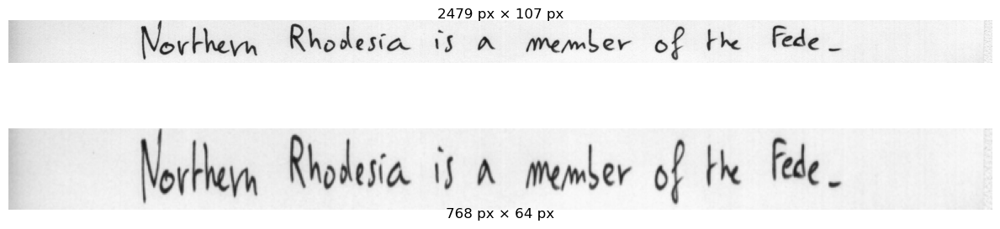

 PIPELINE SEGMENTASI BARIS TULISAN TANGAN
 Grayscale -> Blur -> Threshold -> Line Removal
 -> Segmentasi -> Resize -> Normalize
[LOAD] Gambar berhasil dibaca: 2479x2102 piksel
[GRAY] Shape sebelum: (2102, 2479, 3)  -->  Shape setelah: (2102, 2479)
[BLUR] Gaussian Blur kernel 3x3 diterapkan
[BINARIZE] Piksel foreground (putih): 161173 (3.1%)
[LINE REMOVAL - Morph] Piksel garis dihapus (morph): 7046
[LINE REMOVAL - Hough] Garis tipis dihapus (hough): 136 segmen
[PROJECTION] Savitzky-Golay filter window=51 diterapkan
  Max proyeksi: 413.2  |  Mean non-zero: 73.3
[SEGMENT] Threshold proyeksi: 41.32
[SEGMENT] Kandidat segmen: 9 segmen
[SEGMENT] Padding adaptif: atas=18px  bawah=24px
[SEGMENT] Total baris terdeteksi: 9

[RESIZE] Target ukuran: 768x64px
  [RESIZE] Baris 1: 2479x122px  -->  768x64px
  [RESIZE] Baris 2: 2479x113px  -->  768x64px
  [RESIZE] Baris 3: 2479x120px  -->  768x64px
  [RESIZE] Baris 4: 2479x120px  -->  768x64px
  [RESIZE] Baris 5: 2479x116px  -->  768x64px
  [RESIZE] Ba

C:\Users\ASUS\AppData\Local\Temp\ipykernel_10868\2125362.py:348: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


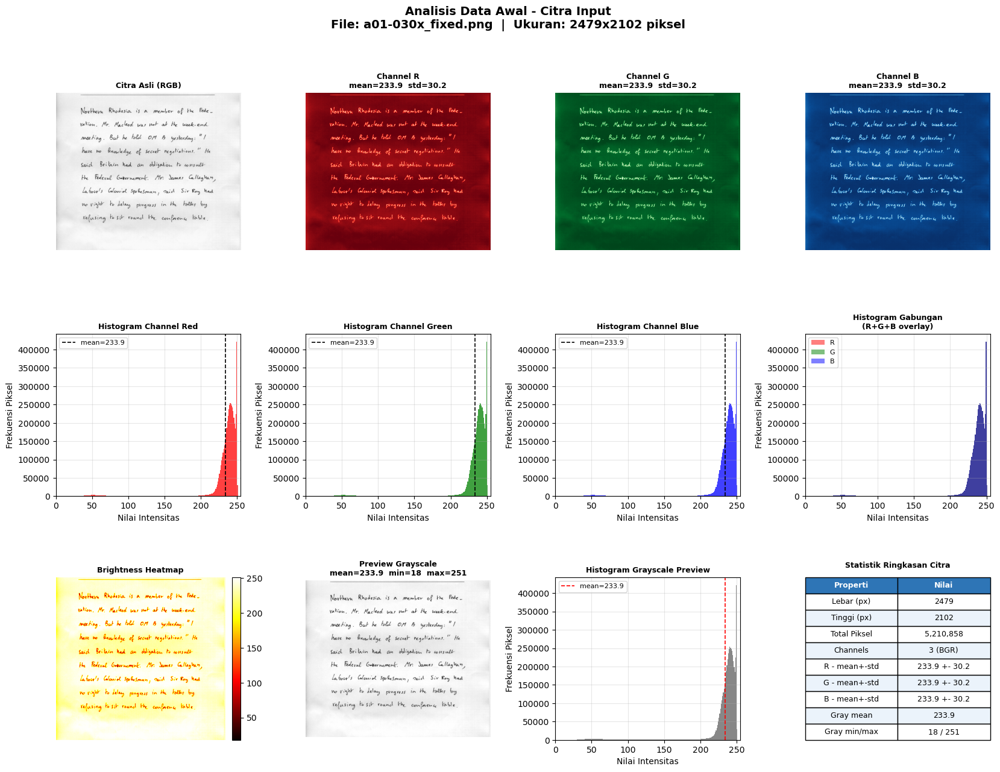

[VIS] Input Overview ditampilkan


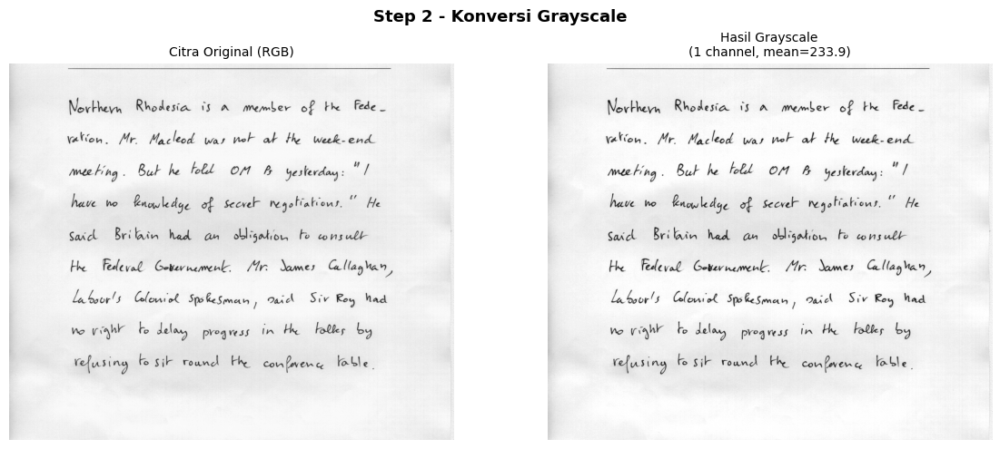

[VIS] Step 2 Grayscale ditampilkan


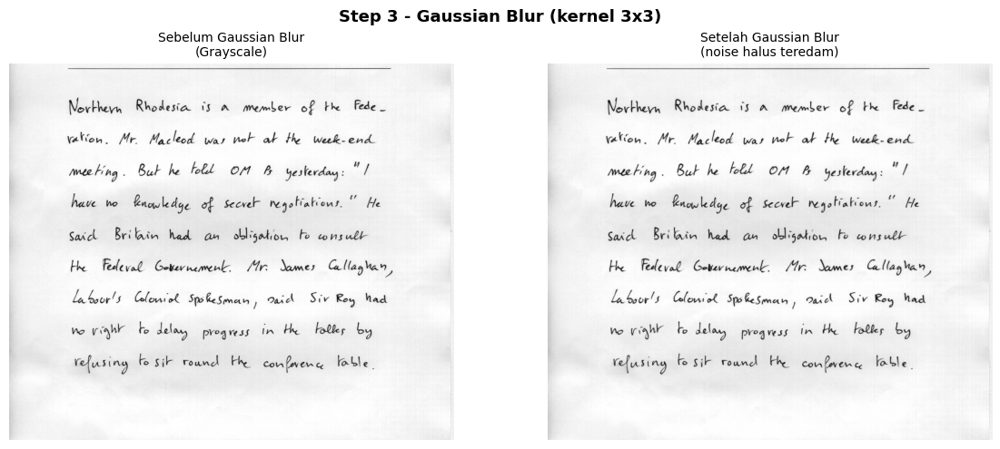

[VIS] Step 3 Gaussian Blur ditampilkan


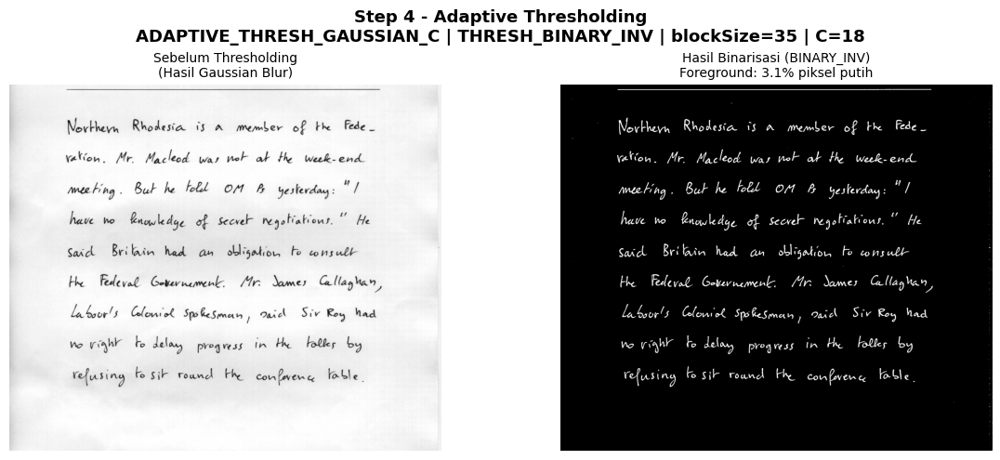

[VIS] Step 4 Adaptive Threshold ditampilkan


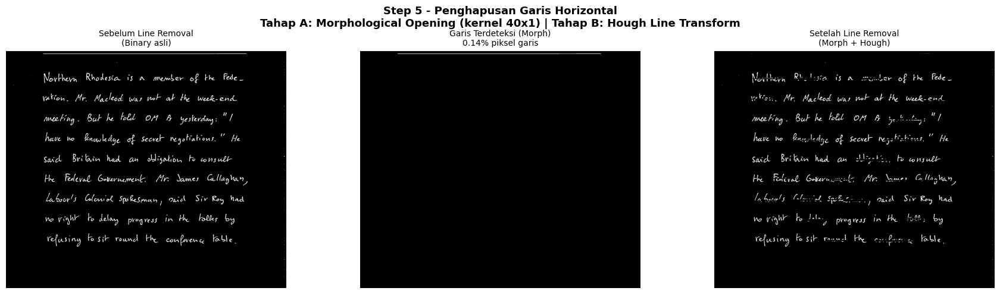

[VIS] Step 5 Line Removal ditampilkan


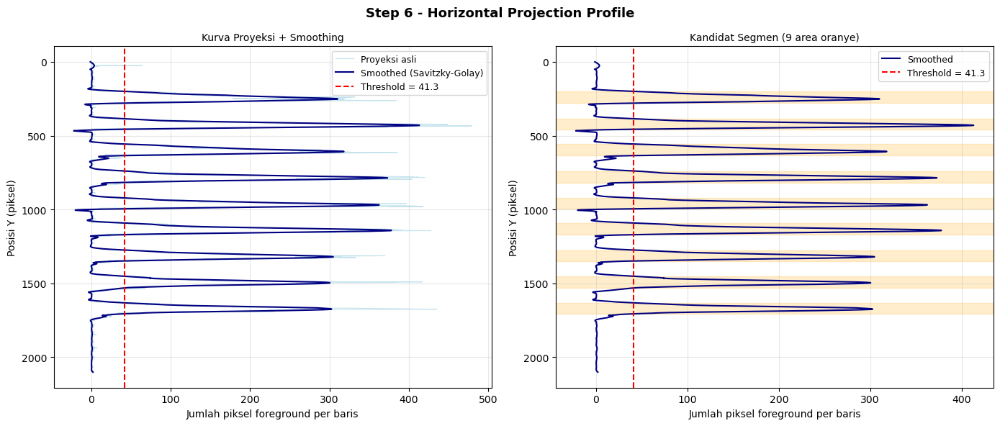

[VIS] Step 6 Projection Profile ditampilkan


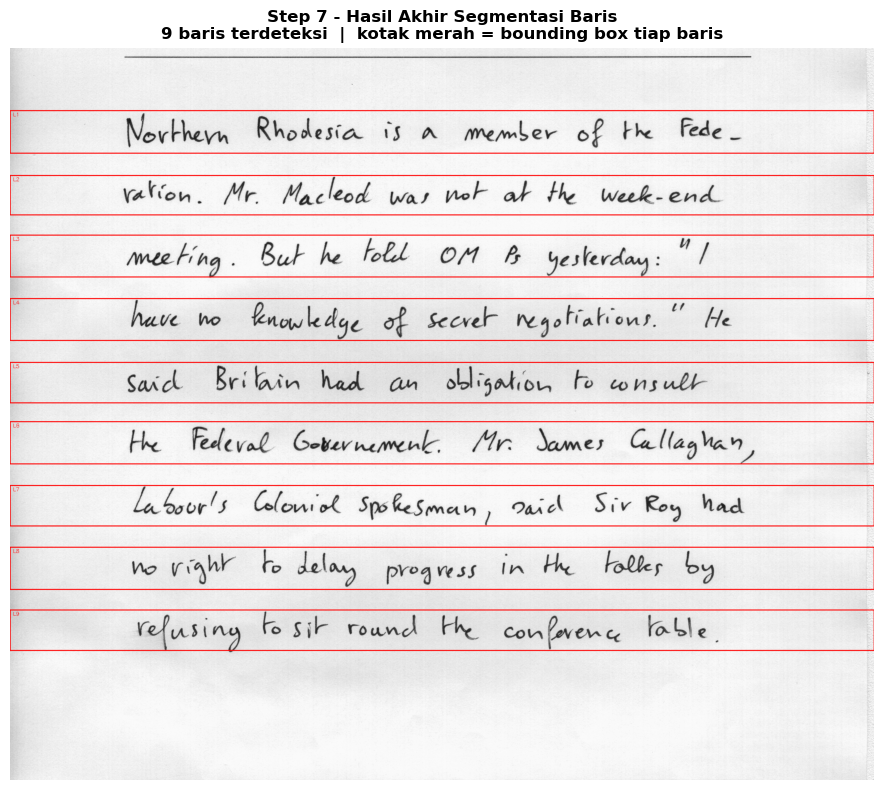

[VIS] Step 7 Hasil Segmentasi ditampilkan


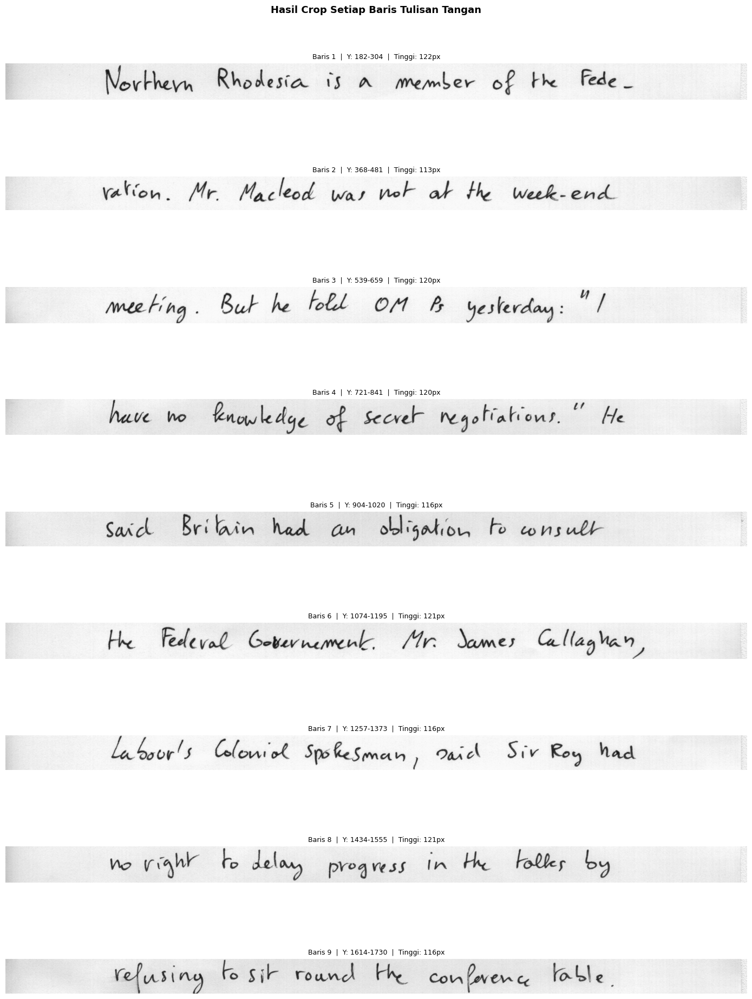

[VIS] Crops (9 baris) ditampilkan


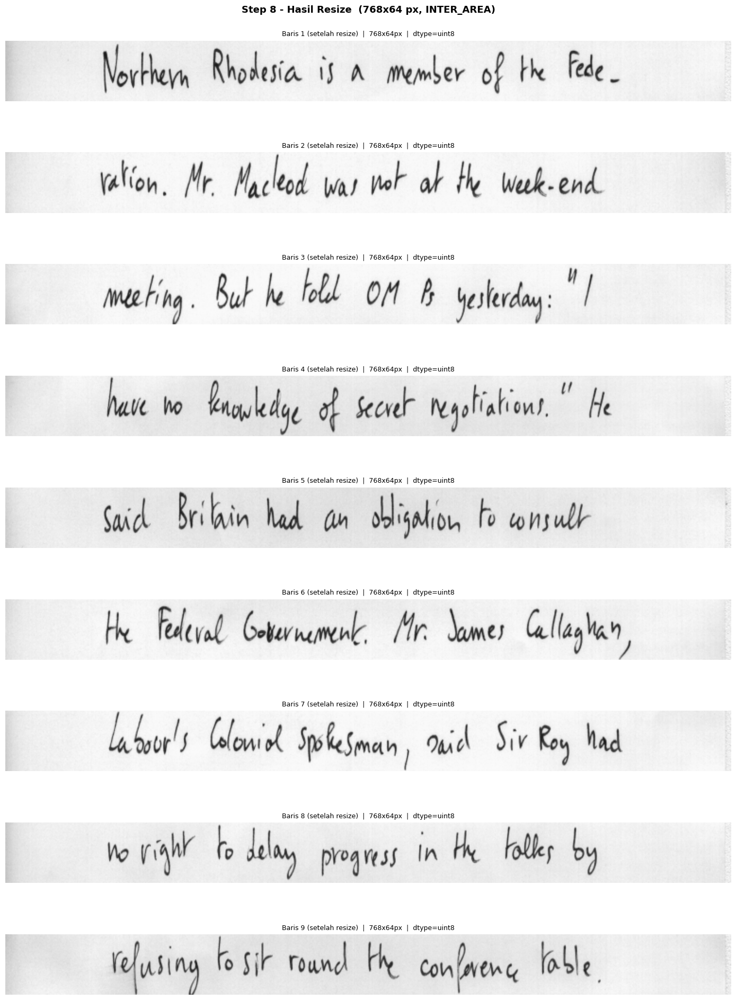

[VIS] Step 8 Resize (9 baris) ditampilkan


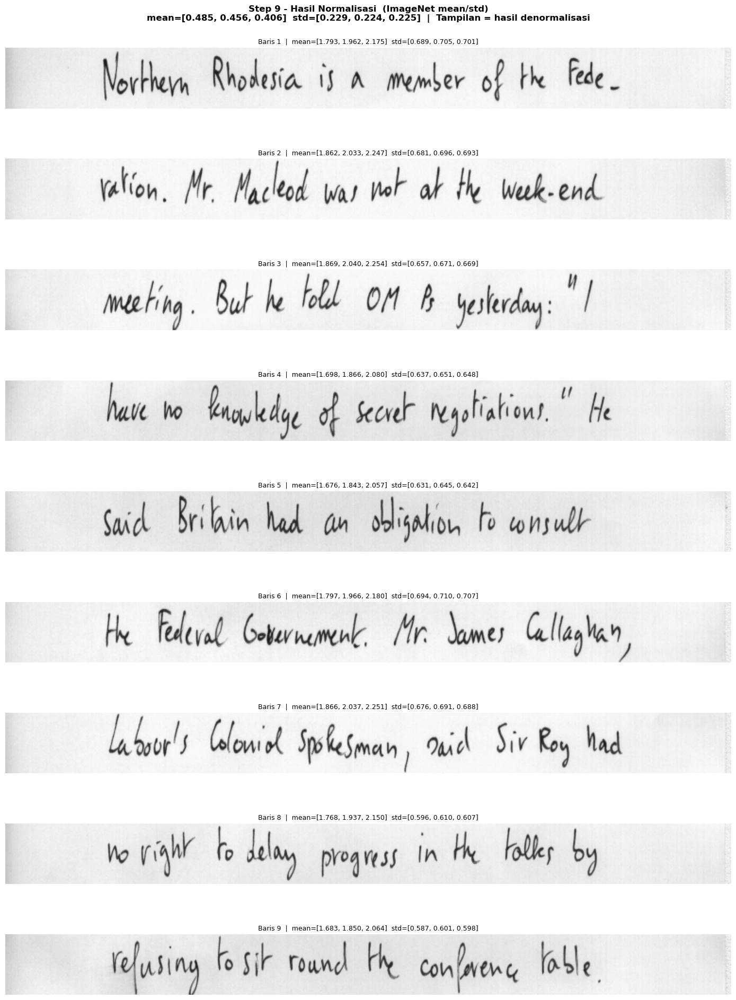

[VIS] Step 9 Normalize (9 baris) ditampilkan


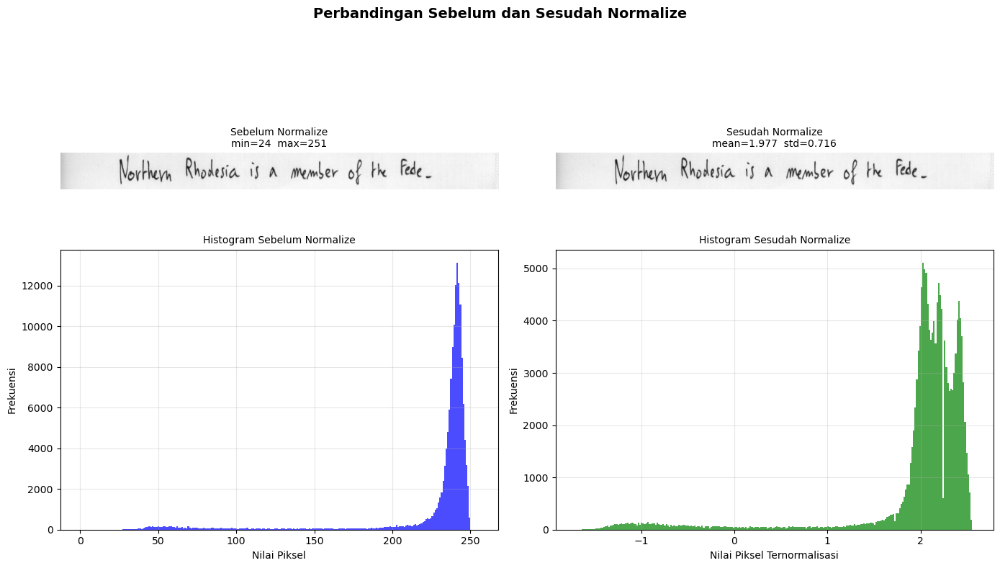

[VIS] Before vs After Normalize ditampilkan
[VIS] Semua visualisasi selesai.


In [5]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import signal
import os
from tqdm import tqdm



# KONSTANTA PREPROCESSING

MEAN    = [0.485, 0.456, 0.406]
STD     = [0.229, 0.224, 0.225]
IMG_H   = 64
IMG_W   = 768



# STEP 1: LOAD GAMBAR

def load_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")
    H, W = img.shape[:2]
    print(f"[LOAD] Gambar berhasil dibaca: {W}x{H} piksel")
    return img



# STEP 2: KONVERSI GRAYSCALE

def convert_to_grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print(f"[GRAY] Shape sebelum: {img.shape}  -->  Shape setelah: {gray.shape}")
    return gray



# STEP 3: GAUSSIAN BLUR (DENOISING)

def apply_gaussian_blur(gray):
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    print(f"[BLUR] Gaussian Blur kernel 3x3 diterapkan")
    return blurred



# STEP 4: ADAPTIVE THRESHOLDING (BINARISASI)

def adaptive_threshold(blurred):
    binary = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=35,
        C=18
    )
    white_pixels = np.sum(binary == 255)
    total_pixels = binary.size
    print(f"[BINARIZE] Piksel foreground (putih): {white_pixels} ({100*white_pixels/total_pixels:.1f}%)")
    return binary



# STEP 5: PENGHAPUSAN GARIS HORIZONTAL

def remove_horizontal_lines(binary):
    result = binary.copy()

    # -- Tahap A: Morphological --
    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (40, 1))
    detected_morph = cv2.morphologyEx(result, cv2.MORPH_OPEN, kernel_h, iterations=2)
    result = cv2.subtract(result, detected_morph)
    morph_pixels = np.sum(detected_morph == 255)
    print(f"[LINE REMOVAL - Morph] Piksel garis dihapus (morph): {morph_pixels}")

    # -- Tahap B: Hough --
    lines = cv2.HoughLinesP(result, 1, np.pi / 180, 80,
                             minLineLength=150, maxLineGap=20)
    removed_hough = 0
    if lines is not None:
        for l in lines:
            x1, y1, x2, y2 = l[0]
            angle = abs(np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi)
            if angle < 8 or angle > 172:
                cv2.line(result, (x1, y1), (x2, y2), 0, 3)
                removed_hough += 1
    print(f"[LINE REMOVAL - Hough] Garis tipis dihapus (hough): {removed_hough} segmen")

    return result, detected_morph, removed_hough



# STEP 6: PROYEKSI HORIZONTAL (HORIZONTAL PROJECTION PROFILE)

def horizontal_projection(binary_clean, H, W):
    hist = cv2.reduce(binary_clean, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32F).flatten() / 255.0

    window = min(51, len(hist) if len(hist) % 2 == 1 else len(hist) - 1)
    if window >= 3:
        hist_smooth = signal.savgol_filter(hist, window, 3)
    else:
        hist_smooth = hist.copy()

    print(f"[PROJECTION] Savitzky-Golay filter window={window} diterapkan")
    print(f"  Max proyeksi: {hist_smooth.max():.1f}  |  Mean non-zero: {hist_smooth[hist_smooth>0].mean():.1f}")
    return hist, hist_smooth



# STEP 7: DETEKSI DAN SEGMENTASI BARIS

def detect_and_segment_lines(binary_clean, hist_smooth, H, W):
    nonzero = hist_smooth[hist_smooth > 0]
    if len(nonzero) > 0:
        threshold = max(np.mean(nonzero) * 0.3, np.max(hist_smooth) * 0.1)
    else:
        threshold = np.max(hist_smooth) * 0.1
    print(f"[SEGMENT] Threshold proyeksi: {threshold:.2f}")

    # -- Segmentasi awal --
    raw_segments = []
    in_line = False
    start = 0
    for i, val in enumerate(hist_smooth):
        if val > threshold and not in_line:
            start = i
            in_line = True
        elif val <= threshold and in_line:
            raw_segments.append((start, i))
            in_line = False
    if in_line:
        raw_segments.append((start, len(hist_smooth)))
    print(f"[SEGMENT] Kandidat segmen: {len(raw_segments)} segmen")

    # -- Adaptive padding --
    if raw_segments:
        avg_h = np.mean([y2 - y1 for y1, y2 in raw_segments])
        pad_top = max(int(avg_h * 0.2), 18)
        pad_bot = max(int(avg_h * 0.32), 22)
    else:
        pad_top, pad_bot = 18, 22
    print(f"[SEGMENT] Padding adaptif: atas={pad_top}px  bawah={pad_bot}px")

    final = []
    for i, (y1, y2) in enumerate(raw_segments):
        y1p = y1 - pad_top
        y2p = y2 + pad_bot
        if i > 0:
            y1p = max(y1p, raw_segments[i - 1][1])
        if i < len(raw_segments) - 1:
            y2p = min(y2p, raw_segments[i + 1][0])
        final.append((max(0, y1p), min(H, y2p)))

    print(f"[SEGMENT] Total baris terdeteksi: {len(final)}")
    return final, threshold, raw_segments



# STEP 8: RESIZE SETIAP CROP BARIS
#   Setiap crop diubah ke ukuran tetap (IMG_W x IMG_H).
#   Aspek rasio TIDAK dipertahankan agar semua tensor seragam (batch-friendly).
#   Output: list of np.ndarray uint8 shape (IMG_H, IMG_W, 3) dalam ruang BGR.

def resize_lines(img, final_lines,
                 target_h: int = IMG_H,
                 target_w: int = IMG_W):
    """
    Crop tiap baris dari `img` lalu resize ke (target_w, target_h).

    Returns
    -------
    resized_crops : list of np.ndarray
        Shape (target_h, target_w, 3), dtype uint8, ruang BGR.
    """
    resized_crops = []
    for idx, (y1, y2) in enumerate(final_lines):
        crop = img[y1:y2, :]                                   # crop baris
        resized = cv2.resize(crop, (target_w, target_h),
                             interpolation=cv2.INTER_AREA)      # INTER_AREA bagus untuk downscale
        resized_crops.append(resized)
        print(f"  [RESIZE] Baris {idx+1}: {crop.shape[1]}x{crop.shape[0]}px  -->  "
              f"{target_w}x{target_h}px")

    print(f"[RESIZE] {len(resized_crops)} crop di-resize ke {target_w}x{target_h}")
    return resized_crops



# STEP 9: NORMALISASI (ImageNet mean/std)
#   Konversi BGR -> RGB -> float32 [0,1] -> subtract mean -> divide std
#   Output: list of np.ndarray float32 shape (IMG_H, IMG_W, 3) — siap masuk model.

def normalize_lines(resized_crops,
                    mean: list = MEAN,
                    std:  list = STD):
    """
    Normalisasi setiap crop dengan mean & std per-channel (format RGB).

    Formula  : output = (pixel / 255.0 - mean) / std
    Channel  : dikonversi BGR -> RGB sebelum normalisasi.

    Returns
    -------
    norm_crops : list of np.ndarray
        Shape (IMG_H, IMG_W, 3), dtype float32.
    """
    mean_arr = np.array(mean, dtype=np.float32)   # shape (3,)
    std_arr  = np.array(std,  dtype=np.float32)   # shape (3,)

    norm_crops = []
    for idx, crop_bgr in enumerate(resized_crops):
        crop_rgb   = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)   # BGR -> RGB
        crop_f32   = crop_rgb.astype(np.float32) / 255.0          # [0, 1]
        normalized = (crop_f32 - mean_arr) / std_arr              # subtract mean, divide std
        norm_crops.append(normalized)

        ch_means = normalized.mean(axis=(0, 1))
        ch_stds  = normalized.std(axis=(0, 1))
        print(f"  [NORM] Baris {idx+1}: "
              f"mean=[{ch_means[0]:.3f}, {ch_means[1]:.3f}, {ch_means[2]:.3f}]  "
              f"std=[{ch_stds[0]:.3f}, {ch_stds[1]:.3f}, {ch_stds[2]:.3f}]")

    print(f"[NORM] {len(norm_crops)} crop dinormalisasi  |  dtype={norm_crops[0].dtype}  "
          f"shape={norm_crops[0].shape}")
    return norm_crops



# VISUALISASI PER STEP (TAMPIL SAJA, TIDAK DISIMPAN)


def _show(fig, label):
    plt.show()
    plt.close(fig)
    print(f"[VIS] {label} ditampilkan")


def vis_input_overview(img, image_path):
    H, W = img.shape[:2]
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    b, g, r = cv2.split(img)
    mean_r, std_r = r.mean(), r.std()
    mean_g, std_g = g.mean(), g.std()
    mean_b, std_b = b.mean(), b.std()
    gray_preview = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    print(f"[INPUT VIS] Ukuran: {W}x{H}px  |  "
          f"R: {mean_r:.1f}+-{std_r:.1f}  "
          f"G: {mean_g:.1f}+-{std_g:.1f}  "
          f"B: {mean_b:.1f}+-{std_b:.1f}")

    fig = plt.figure(figsize=(20, 14))
    fig.suptitle(
        f"Analisis Data Awal - Citra Input\n"
        f"File: {os.path.basename(image_path)}  |  Ukuran: {W}x{H} piksel",
        fontsize=14, fontweight='bold', y=0.98
    )
    gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.5, wspace=0.35)

    ax_rgb = fig.add_subplot(gs[0, 0])
    ax_rgb.imshow(img_rgb)
    ax_rgb.set_title("Citra Asli (RGB)", fontsize=9, fontweight='bold')
    ax_rgb.axis('off')

    for col, (ch, cmap, title) in enumerate([
        (r, 'Reds',   f"Channel R\nmean={mean_r:.1f}  std={std_r:.1f}"),
        (g, 'Greens', f"Channel G\nmean={mean_g:.1f}  std={std_g:.1f}"),
        (b, 'Blues',  f"Channel B\nmean={mean_b:.1f}  std={std_b:.1f}"),
    ], start=1):
        ax = fig.add_subplot(gs[0, col])
        ax.imshow(ch, cmap=cmap)
        ax.set_title(title, fontsize=9, fontweight='bold')
        ax.axis('off')

    for col, (color, ch, label) in enumerate([
        ('r', r, 'Red'), ('g', g, 'Green'), ('b', b, 'Blue')
    ]):
        ax = fig.add_subplot(gs[1, col])
        ax.hist(ch.ravel(), bins=256, range=(0, 255), color=color, alpha=0.75)
        ax.axvline(ch.mean(), color='black', linestyle='--', linewidth=1.2,
                   label=f'mean={ch.mean():.1f}')
        ax.set_xlim(0, 255)
        ax.set_xlabel("Nilai Intensitas"); ax.set_ylabel("Frekuensi Piksel")
        ax.set_title(f"Histogram Channel {label}", fontsize=9, fontweight='bold')
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    ax_all = fig.add_subplot(gs[1, 3])
    ax_all.hist(r.ravel(), bins=256, range=(0,255), color='red',   alpha=0.5, label='R')
    ax_all.hist(g.ravel(), bins=256, range=(0,255), color='green', alpha=0.5, label='G')
    ax_all.hist(b.ravel(), bins=256, range=(0,255), color='blue',  alpha=0.5, label='B')
    ax_all.set_xlim(0, 255)
    ax_all.set_xlabel("Nilai Intensitas"); ax_all.set_ylabel("Frekuensi Piksel")
    ax_all.set_title("Histogram Gabungan\n(R+G+B overlay)", fontsize=9, fontweight='bold')
    ax_all.legend(fontsize=8); ax_all.grid(True, alpha=0.3)

    ax_heat = fig.add_subplot(gs[2, 0])
    hm = ax_heat.imshow(gray_preview, cmap='hot', aspect='auto')
    plt.colorbar(hm, ax=ax_heat, fraction=0.046, pad=0.04)
    ax_heat.set_title("Brightness Heatmap", fontsize=9, fontweight='bold')
    ax_heat.axis('off')

    ax_gray = fig.add_subplot(gs[2, 1])
    ax_gray.imshow(gray_preview, cmap='gray')
    ax_gray.set_title(f"Preview Grayscale\nmean={gray_preview.mean():.1f}  "
                      f"min={gray_preview.min()}  max={gray_preview.max()}",
                      fontsize=9, fontweight='bold')
    ax_gray.axis('off')

    ax_gh = fig.add_subplot(gs[2, 2])
    ax_gh.hist(gray_preview.ravel(), bins=256, range=(0,255), color='dimgray', alpha=0.8)
    ax_gh.axvline(gray_preview.mean(), color='red', linestyle='--', linewidth=1.2,
                  label=f'mean={gray_preview.mean():.1f}')
    ax_gh.set_xlim(0, 255)
    ax_gh.set_xlabel("Nilai Intensitas"); ax_gh.set_ylabel("Frekuensi Piksel")
    ax_gh.set_title("Histogram Grayscale Preview", fontsize=9, fontweight='bold')
    ax_gh.legend(fontsize=8); ax_gh.grid(True, alpha=0.3)

    ax_tbl = fig.add_subplot(gs[2, 3])
    ax_tbl.axis('off')
    stats_data = [
        ["Properti",      "Nilai"],
        ["Lebar (px)",    str(W)],
        ["Tinggi (px)",   str(H)],
        ["Total Piksel",  f"{W*H:,}"],
        ["Channels",      "3 (BGR)"],
        ["R - mean+-std", f"{mean_r:.1f} +- {std_r:.1f}"],
        ["G - mean+-std", f"{mean_g:.1f} +- {std_g:.1f}"],
        ["B - mean+-std", f"{mean_b:.1f} +- {std_b:.1f}"],
        ["Gray mean",     f"{gray_preview.mean():.1f}"],
        ["Gray min/max",  f"{gray_preview.min()} / {gray_preview.max()}"],
    ]
    tbl = ax_tbl.table(cellText=stats_data[1:], colLabels=stats_data[0],
                       cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_facecolor('#2E75B6')
            cell.set_text_props(color='white', fontweight='bold')
        elif row % 2 == 0:
            cell.set_facecolor('#EBF3FB')
    ax_tbl.set_title("Statistik Ringkasan Citra", fontsize=9, fontweight='bold', pad=12)

    plt.tight_layout()
    _show(fig, "Input Overview")


def vis_step2_grayscale(img, gray):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 2 - Konversi Grayscale", fontsize=13, fontweight='bold')
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Citra Original (RGB)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(gray, cmap='gray')
    axes[1].set_title(f"Hasil Grayscale\n(1 channel, mean={gray.mean():.1f})", fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 2 Grayscale")


def vis_step3_blur(gray, blurred):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 3 - Gaussian Blur (kernel 3x3)", fontsize=13, fontweight='bold')
    axes[0].imshow(gray, cmap='gray')
    axes[0].set_title("Sebelum Gaussian Blur\n(Grayscale)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(blurred, cmap='gray')
    axes[1].set_title("Setelah Gaussian Blur\n(noise halus teredam)", fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 3 Gaussian Blur")


def vis_step4_threshold(blurred, binary_raw):
    white_pct = 100 * np.sum(binary_raw == 255) / binary_raw.size
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Step 4 - Adaptive Thresholding\n"
                 "ADAPTIVE_THRESH_GAUSSIAN_C | THRESH_BINARY_INV | blockSize=35 | C=18",
                 fontsize=13, fontweight='bold')
    axes[0].imshow(blurred, cmap='gray')
    axes[0].set_title("Sebelum Thresholding\n(Hasil Gaussian Blur)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(binary_raw, cmap='gray')
    axes[1].set_title(f"Hasil Binarisasi (BINARY_INV)\nForeground: {white_pct:.1f}% piksel putih",
                      fontsize=10)
    axes[1].axis('off')
    plt.tight_layout()
    _show(fig, "Step 4 Adaptive Threshold")


def vis_step5_line_removal(binary_raw, detected_morph, binary_no_lines):
    morph_pct = 100 * np.sum(detected_morph == 255) / detected_morph.size
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Step 5 - Penghapusan Garis Horizontal\n"
                 "Tahap A: Morphological Opening (kernel 40x1) | Tahap B: Hough Line Transform",
                 fontsize=13, fontweight='bold')
    axes[0].imshow(binary_raw, cmap='gray')
    axes[0].set_title("Sebelum Line Removal\n(Binary asli)", fontsize=10)
    axes[0].axis('off')
    axes[1].imshow(detected_morph, cmap='gray')
    axes[1].set_title(f"Garis Terdeteksi (Morph)\n{morph_pct:.2f}% piksel garis", fontsize=10)
    axes[1].axis('off')
    axes[2].imshow(binary_no_lines, cmap='gray')
    axes[2].set_title("Setelah Line Removal\n(Morph + Hough)", fontsize=10)
    axes[2].axis('off')
    plt.tight_layout()
    _show(fig, "Step 5 Line Removal")


def vis_step6_projection(hist, hist_smooth, threshold, raw_segments):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Step 6 - Horizontal Projection Profile", fontsize=13, fontweight='bold')
    axes[0].plot(hist, range(len(hist)),
                 color='lightblue', alpha=0.7, linewidth=0.8, label='Proyeksi asli')
    axes[0].plot(hist_smooth, range(len(hist_smooth)),
                 color='navy', linewidth=1.5, label='Smoothed (Savitzky-Golay)')
    axes[0].axvline(threshold, color='red', linestyle='--', linewidth=1.5,
                    label=f'Threshold = {threshold:.1f}')
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Jumlah piksel foreground per baris")
    axes[0].set_ylabel("Posisi Y (piksel)")
    axes[0].set_title("Kurva Proyeksi + Smoothing", fontsize=10)
    axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

    axes[1].plot(hist_smooth, range(len(hist_smooth)),
                 color='navy', linewidth=1.5, label='Smoothed')
    axes[1].axvline(threshold, color='red', linestyle='--', linewidth=1.5,
                    label=f'Threshold = {threshold:.1f}')
    for (y1, y2) in raw_segments:
        axes[1].axhspan(y1, y2, alpha=0.2, color='orange')
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Jumlah piksel foreground per baris")
    axes[1].set_ylabel("Posisi Y (piksel)")
    axes[1].set_title(f"Kandidat Segmen ({len(raw_segments)} area oranye)", fontsize=10)
    axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    _show(fig, "Step 6 Projection Profile")


def vis_step7_segmentasi(img, final_lines):
    H, W = img.shape[:2]
    vis_final = img.copy()
    for idx, (y1, y2) in enumerate(final_lines):
        cv2.rectangle(vis_final, (0, y1), (W, y2), (0, 0, 255), 2)
        cv2.putText(vis_final, f"L{idx+1}", (8, y1 + 16),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(cv2.cvtColor(vis_final, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"Step 7 - Hasil Akhir Segmentasi Baris\n"
        f"{len(final_lines)} baris terdeteksi  |  kotak merah = bounding box tiap baris",
        fontsize=12, fontweight='bold'
    )
    ax.axis('off')
    plt.tight_layout()
    _show(fig, "Step 7 Hasil Segmentasi")


def vis_crops(img, final_lines):
    n = len(final_lines)
    if n == 0:
        print("[CROP] Tidak ada baris untuk ditampilkan.")
        return

    fig, axes = plt.subplots(n, 1, figsize=(14, 2.2 * n))
    if n == 1:
        axes = [axes]

    for i, (y1, y2) in enumerate(final_lines):
        crop = img[y1:y2, :]
        axes[i].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[i].set_title(
            f"Baris {i+1}  |  Y: {y1}-{y2}  |  Tinggi: {y2-y1}px", fontsize=9
        )
        axes[i].axis('off')

    plt.suptitle("Hasil Crop Setiap Baris Tulisan Tangan", fontsize=13, fontweight='bold')
    plt.tight_layout()
    _show(fig, f"Crops ({n} baris)")


def vis_step8_resize(resized_crops):
    """Tampilkan semua crop setelah resize ke ukuran seragam (IMG_W x IMG_H)."""
    n = len(resized_crops)
    if n == 0:
        print("[VIS RESIZE] Tidak ada crop untuk ditampilkan.")
        return

    fig, axes = plt.subplots(n, 1, figsize=(14, 2.2 * n))
    if n == 1:
        axes = [axes]

    for i, crop_bgr in enumerate(resized_crops):
        axes[i].imshow(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
        axes[i].set_title(
            f"Baris {i+1} (setelah resize)  |  {crop_bgr.shape[1]}x{crop_bgr.shape[0]}px  "
            f"|  dtype={crop_bgr.dtype}",
            fontsize=9
        )
        axes[i].axis('off')

    plt.suptitle(
        f"Step 8 - Hasil Resize  ({IMG_W}x{IMG_H} px, INTER_AREA)",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    _show(fig, f"Step 8 Resize ({n} baris)")


def vis_step9_normalize(norm_crops):
    """
    Tampilkan crop ternormalisasi.
    Nilai sudah di luar [0,1] sehingga perlu di-denormalisasi untuk display:
        pixel_display = clip((norm * std + mean) * 255, 0, 255)
    """
    n = len(norm_crops)
    if n == 0:
        print("[VIS NORM] Tidak ada crop untuk ditampilkan.")
        return

    mean_arr = np.array(MEAN, dtype=np.float32)
    std_arr  = np.array(STD,  dtype=np.float32)

    fig, axes = plt.subplots(n, 1, figsize=(14, 2.2 * n))
    if n == 1:
        axes = [axes]

    for i, norm in enumerate(norm_crops):
        # denormalisasi untuk keperluan tampil saja
        display = np.clip((norm * std_arr + mean_arr) * 255, 0, 255).astype(np.uint8)
        ch_means = norm.mean(axis=(0, 1))
        ch_stds  = norm.std(axis=(0, 1))
        axes[i].imshow(display)
        axes[i].set_title(
            f"Baris {i+1}  |  "
            f"mean=[{ch_means[0]:.3f}, {ch_means[1]:.3f}, {ch_means[2]:.3f}]  "
            f"std=[{ch_stds[0]:.3f}, {ch_stds[1]:.3f}, {ch_stds[2]:.3f}]",
            fontsize=9
        )
        axes[i].axis('off')

    plt.suptitle(
        f"Step 9 - Hasil Normalisasi  (ImageNet mean/std)\n"
        f"mean={MEAN}  std={STD}  |  Tampilan = hasil denormalisasi",
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    _show(fig, f"Step 9 Normalize ({n} baris)")

def vis_before_after_normalize(resized_crops, norm_crops):
    """
    Visualisasi before vs after normalize
    """
    if len(resized_crops) == 0:
        print("[COMPARE NORM] Tidak ada data.")
        return

    mean_arr = np.array(MEAN, dtype=np.float32)
    std_arr  = np.array(STD, dtype=np.float32)

    # ambil crop pertama aja biar simpel
    before_bgr = resized_crops[0]
    before_rgb = cv2.cvtColor(before_bgr, cv2.COLOR_BGR2RGB)

    norm = norm_crops[0]

    # denormalisasi untuk display
    after_display = np.clip(
        (norm * std_arr + mean_arr) * 255,
        0, 255
    ).astype(np.uint8)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    fig.suptitle(
        "Perbandingan Sebelum dan Sesudah Normalize",
        fontsize=14,
        fontweight='bold'
    )

    # =========================
    # BEFORE IMAGE
    # =========================
    axes[0,0].imshow(before_rgb)
    axes[0,0].set_title(
        f"Sebelum Normalize\n"
        f"min={before_rgb.min()}  max={before_rgb.max()}",
        fontsize=10
    )
    axes[0,0].axis('off')

    # =========================
    # AFTER IMAGE
    # =========================
    axes[0,1].imshow(after_display)
    axes[0,1].set_title(
        f"Sesudah Normalize\n"
        f"mean={norm.mean():.3f}  std={norm.std():.3f}",
        fontsize=10
    )
    axes[0,1].axis('off')

    # =========================
    # HIST BEFORE
    # =========================
    axes[1,0].hist(before_rgb.ravel(),
                   bins=256,
                   range=(0,255),
                   color='blue',
                   alpha=0.7)

    axes[1,0].set_title(
        "Histogram Sebelum Normalize",
        fontsize=10
    )
    axes[1,0].set_xlabel("Nilai Piksel")
    axes[1,0].set_ylabel("Frekuensi")
    axes[1,0].grid(True, alpha=0.3)

    # =========================
    # HIST AFTER
    # =========================
    axes[1,1].hist(norm.ravel(),
                   bins=256,
                   color='green',
                   alpha=0.7)

    axes[1,1].set_title(
        "Histogram Sesudah Normalize",
        fontsize=10
    )
    axes[1,1].set_xlabel("Nilai Piksel Ternormalisasi")
    axes[1,1].set_ylabel("Frekuensi")
    axes[1,1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("[VIS] Before vs After Normalize ditampilkan")


# MAIN PIPELINE

def segment_lines(image_path):

    print("=" * 60)
    print(" PIPELINE SEGMENTASI BARIS TULISAN TANGAN")
    print(" Grayscale -> Blur -> Threshold -> Line Removal")
    print(" -> Segmentasi -> Resize -> Normalize")
    print("=" * 60)

    img = load_image(image_path)
    H, W = img.shape[:2]

    gray              = convert_to_grayscale(img)
    blurred           = apply_gaussian_blur(gray)
    binary_raw        = adaptive_threshold(blurred)
    binary_no_lines, detected_morph, n_hough = remove_horizontal_lines(binary_raw)
    binary_clean      = binary_no_lines

    hist, hist_smooth = horizontal_projection(binary_clean, H, W)

    final_lines, threshold, raw_segs = detect_and_segment_lines(
        binary_clean, hist_smooth, H, W
    )

    # ---- Step 8: Resize ----
    print(f"\n[RESIZE] Target ukuran: {IMG_W}x{IMG_H}px")
    resized_crops = resize_lines(img, final_lines)

    # ---- Step 9: Normalize ----
    print(f"\n[NORM] mean={MEAN}  std={STD}")
    norm_crops = normalize_lines(resized_crops)

    print("\n" + "=" * 60)
    print(f" HASIL AKHIR: {len(final_lines)} baris tulisan terdeteksi")
    print(f" Setiap crop: shape={norm_crops[0].shape}  dtype={norm_crops[0].dtype}")
    print("=" * 60)

    print("\n[VIS] Menampilkan visualisasi per step...")
    vis_input_overview(img, image_path)
    vis_step2_grayscale(img, gray)
    vis_step3_blur(gray, blurred)
    vis_step4_threshold(blurred, binary_raw)
    vis_step5_line_removal(binary_raw, detected_morph, binary_no_lines)
    vis_step6_projection(hist, hist_smooth, threshold, raw_segs)
    vis_step7_segmentasi(img, final_lines)
    vis_crops(img, final_lines)
    vis_step8_resize(resized_crops)       # NEW
    vis_step9_normalize(norm_crops)       # NEW
    vis_before_after_normalize(resized_crops, norm_crops)
    print("[VIS] Semua visualisasi selesai.")

    return final_lines, resized_crops, norm_crops


if __name__ == "__main__":
    segment_lines("cropped_fix/a01-030x_fixed.png")


# ALL

In [ ]:
# STEP 1: LOAD GAMBAR

def load_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")
    return img



# STEP 2: KONVERSI GRAYSCALE

def convert_to_grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return gray



# STEP 3: GAUSSIAN BLUR (DENOISING)

def apply_gaussian_blur(gray):
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    return blurred



# STEP 4: ADAPTIVE THRESHOLDING (BINARISASI)

def adaptive_threshold(blurred):
    binary = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=35,
        C=18
    )
    return binary



# STEP 5: PENGHAPUSAN GARIS HORIZONTAL

def remove_horizontal_lines(binary):
    result = binary.copy()

    # -- Tahap A: Morphological --
    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (40, 1))
    detected_morph = cv2.morphologyEx(result, cv2.MORPH_OPEN, kernel_h, iterations=2)
    result = cv2.subtract(result, detected_morph)

    # -- Tahap B: Hough --
    lines = cv2.HoughLinesP(result, 1, np.pi / 180, 80,
                             minLineLength=150, maxLineGap=20)
    if lines is not None:
        for l in lines:
            x1, y1, x2, y2 = l[0]
            angle = abs(np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi)
            if angle < 8 or angle > 172:
                cv2.line(result, (x1, y1), (x2, y2), 0, 3)

    return result, detected_morph



# STEP 6: PROYEKSI HORIZONTAL

def horizontal_projection(binary_clean, H, W):
    hist = cv2.reduce(binary_clean, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32F).flatten() / 255.0

    window = min(51, len(hist) if len(hist) % 2 == 1 else len(hist) - 1)
    if window >= 3:
        hist_smooth = signal.savgol_filter(hist, window, 3)
    else:
        hist_smooth = hist.copy()

    return hist, hist_smooth



# STEP 7: DETEKSI DAN SEGMENTASI BARIS

def detect_and_segment_lines(binary_clean, hist_smooth, H, W):
    nonzero = hist_smooth[hist_smooth > 0]
    if len(nonzero) > 0:
        threshold = max(np.mean(nonzero) * 0.3, np.max(hist_smooth) * 0.1)
    else:
        threshold = np.max(hist_smooth) * 0.1

    # -- Segmentasi awal --
    raw_segments = []
    in_line = False
    start = 0
    for i, val in enumerate(hist_smooth):
        if val > threshold and not in_line:
            start = i
            in_line = True
        elif val <= threshold and in_line:
            raw_segments.append((start, i))
            in_line = False
    if in_line:
        raw_segments.append((start, len(hist_smooth)))

    # -- Filter --
    filtered = []
    for (y1, y2) in raw_segments:
        h = y2 - y1
        region = binary_clean[y1:y2, :]
        content = np.sum(region) / 255.0
        density = content / (W * h) if W * h > 0 else 0
        if h > 25 and content > 400 and density > 0.01:
            filtered.append((y1, y2))

    # -- Merge --
    merged = []
    if filtered:
        cur = list(filtered[0])
        for (y1, y2) in filtered[1:]:
            if y1 - cur[1] < 12:
                cur[1] = y2
            else:
                merged.append(tuple(cur))
                cur = [y1, y2]
        merged.append(tuple(cur))

    # -- Adaptive padding --
    if merged:
        avg_h = np.mean([y2 - y1 for y1, y2 in merged])
        pad_top = max(int(avg_h * 0.2), 18)
        pad_bot = max(int(avg_h * 0.32), 22)
    else:
        pad_top, pad_bot = 18, 22

    final = []
    for i, (y1, y2) in enumerate(merged):
        y1p = y1 - pad_top
        y2p = y2 + pad_bot
        if i > 0:
            y1p = max(y1p, merged[i - 1][1])
        if i < len(merged) - 1:
            y2p = min(y2p, merged[i + 1][0])
        final.append((max(0, y1p), min(H, y2p)))

    return final, threshold, raw_segments, filtered, merged



# SEGMENT LINES (TANPA VISUALISASI - UNTUK BATCH)

def segment_lines(image_path, verbose=False):
    """
    Pipeline segmentasi baris tanpa visualisasi.
    verbose=True untuk print log per gambar.
    """
    img = load_image(image_path)
    H, W = img.shape[:2]

    gray              = convert_to_grayscale(img)
    blurred           = apply_gaussian_blur(gray)
    binary_raw        = adaptive_threshold(blurred)
    binary_clean, _   = remove_horizontal_lines(binary_raw)
    hist, hist_smooth = horizontal_projection(binary_clean, H, W)
    final_lines, threshold, raw_segs, filt_segs, merged_segs = detect_and_segment_lines(
        binary_clean, hist_smooth, H, W
    )

    if verbose:
        print(f"  -> {len(final_lines)} baris terdeteksi  [{W}x{H}px]")

    return final_lines



# PROCESS SEMUA DATA DARI CSV

def process_dataset(csv_path, image_folder, output_folder=None, verbose=False):
    df = pd.read_csv(csv_path)
    print(f"[INFO] Total gambar dalam CSV : {len(df)}")
    print(f"[INFO] Image folder           : {image_folder}")

    if output_folder:
        os.makedirs(output_folder, exist_ok=True)
        print(f"[INFO] Output crop disimpan ke : {output_folder}")

    results = []
    skipped = []

    for _, row in tqdm(df.iterrows(), total=len(df), desc="Segmentasi"):
        filename       = row["image_path"]
        writer_id      = row["writer_id"]

        # ✅ Ambil nama file saja, buang prefix path dari CSV (./data/000/...)
        clean_filename = os.path.basename(filename)
        full_path      = os.path.join(image_folder, clean_filename)

        # --- Skip jika file tidak ada ---
        if not os.path.exists(full_path):
            if verbose:
                print(f"\n[WARN] File tidak ditemukan, dilewati: {full_path}")
            skipped.append(filename)
            continue

        try:
            lines = segment_lines(full_path, verbose=verbose)
        except Exception as e:
            print(f"\n[ERROR] Gagal memproses {clean_filename}: {e}")
            skipped.append(filename)
            continue

        # --- Tidak ada baris terdeteksi ---
        if len(lines) == 0:
            if verbose:
                print(f"\n[WARN] Tidak ada baris terdeteksi: {clean_filename}")
            skipped.append(filename)
            continue

        for idx, (y1, y2) in enumerate(lines):
            results.append({
                "image_path": clean_filename,
                "writer_id":  writer_id,
                "line_id":    idx + 1,
                "y1":         y1,
                "y2":         y2
            })

            # --- Simpan crop jika output_folder diset ---
            if output_folder:
                img       = cv2.imread(full_path)
                crop      = img[y1:y2, :]
                base_name = os.path.splitext(clean_filename)[0]
                save_name = f"{base_name}_line{idx+1}.png"
                save_path = os.path.join(output_folder, save_name)
                cv2.imwrite(save_path, crop)

    df_result = pd.DataFrame(results)

    # --- Ringkasan akhir ---
    print("\n" + "=" * 50)
    print(f"  SELESAI")
    print(f"  Total gambar dalam CSV    : {len(df)}")
    print(f"  Total gambar diproses     : {len(df) - len(skipped)}")
    print(f"  Total gambar dilewati     : {len(skipped)}")
    print(f"  Total baris terdeteksi    : {len(df_result)}")
    if len(df_result) > 0:
        avg = df_result.groupby("image_path")["line_id"].max().mean()
        print(f"  Rata-rata baris/gambar    : {avg:.1f}")
    print("=" * 50)

    if skipped:
        print(f"\n[WARN] {len(skipped)} file dilewati (tidak ditemukan / gagal / 0 baris):")
        for f in skipped[:20]:           # tampilkan maks 20 supaya tidak membanjiri output
            print(f"  - {f}")
        if len(skipped) > 20:
            print(f"  ... dan {len(skipped) - 20} file lainnya")

    return df_result



# MAIN

if __name__ == "__main__":
    df_lines = process_dataset(
        csv_path="metadata_cropped.csv",
        image_folder="cropped_fix",
        output_folder="lines_output",  # set None kalau tidak mau save crop
        verbose=False
    )
    df_lines.to_csv("metadata_lines.csv", index=False)
    print(f"\n✓ metadata_lines.csv tersimpan  ({len(df_lines)} baris total)")

[INFO] Total gambar dalam CSV : 1539
[INFO] Image folder           : cropped_fix
[INFO] Output crop disimpan ke : lines_output
Segmentasi: 100%|██████████| 1539/1539 [51:04<00:00,  1.99s/it]

  SELESAI
  Total gambar dalam CSV    : 1539
  Total gambar diproses     : 1539
  Total gambar dilewati     : 0
  Total baris terdeteksi    : 13381
  Rata-rata baris/gambar    : 8.7

✓ metadata_lines.csv tersimpan  (13381 baris total) 


In [17]:
import os
from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

# =========================
# PARAM
# =========================
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
IMG_H, IMG_W = 64, 768

# =========================
# TRANSFORM (pipeline kamu)
# =========================
def get_simclr_transform():
    return transforms.Compose([
        transforms.Resize((IMG_H, IMG_W)),
        transforms.Grayscale(num_output_channels=3),
        transforms.RandomAffine(degrees=3, shear=5, translate=(0.02, 0.02)),
        transforms.RandomCrop((IMG_H, IMG_W), padding=4),
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.5)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
        transforms.RandomErasing(p=0.2, scale=(0.01, 0.05)),
    ])

transform = get_simclr_transform()

# =========================
# DENORMALIZE (biar bisa dilihat)
# =========================
def denormalize(tensor):
    mean = torch.tensor(MEAN).view(3,1,1)
    std = torch.tensor(STD).view(3,1,1)
    return tensor * std + mean

# =========================
# SAVE CLEAN IMAGE
# =========================
def save_clean(img_array, filename):
    plt.figure()
    plt.imshow(img_array)
    plt.axis('off')
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close()

# =========================
# LOAD IMAGE
# =========================
img_path = "lines_output/a01-030x_fixed_line1.png"
img = Image.open(img_path).convert("RGB")

# =========================
# SIMCLR VIEW
# =========================
view1 = transform(img)
view2 = transform(img)

# =========================
# DENORMALIZE
# =========================
v1 = denormalize(view1).permute(1,2,0).numpy()
v2 = denormalize(view2).permute(1,2,0).numpy()

v1 = np.clip(v1, 0, 1)
v2 = np.clip(v2, 0, 1)

# =========================
# SAVE
# =========================
save_clean(v1, "Gambar_view1.png")
save_clean(v2, "Gambar_view2.png")

print("✅ View 1 & View 2 berhasil dibuat dan disimpan!")

✅ View 1 & View 2 berhasil dibuat dan disimpan!


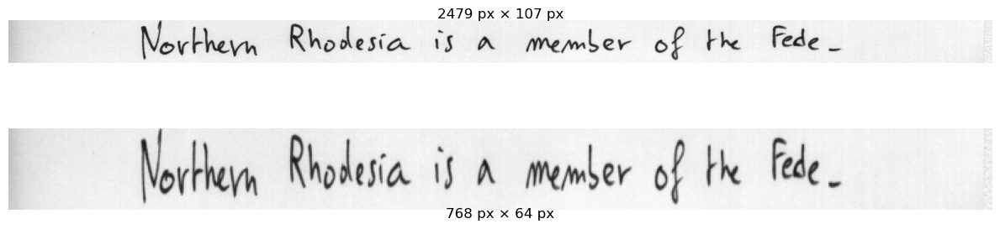

In [2]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

# =========================
# PARAM
# =========================
IMG_H, IMG_W = 64, 768

# =========================
# LOAD IMAGE
# =========================
img_path = "lines_output/a01-030x_fixed_line1.png"
img = Image.open(img_path).convert("RGB")

# ambil ukuran asli
orig_w, orig_h = img.size

# =========================
# RESIZE
# =========================
resize_tf = transforms.Resize((IMG_H, IMG_W))
img_resize = resize_tf(img)

# =========================
# VISUALISASI
# =========================
plt.figure(figsize=(12,4))

# ===== BEFORE =====
plt.subplot(2,1,1)
plt.imshow(img)
plt.axis('off')

# teks ukuran atas
plt.text(
    0.5, 1.05,
    f"{orig_w} px × {orig_h} px",
    transform=plt.gca().transAxes,
    ha='center',
    fontsize=12
)

# ===== AFTER =====
plt.subplot(2,1,2)
plt.imshow(img_resize)
plt.axis('off')

# teks ukuran bawah
plt.text(
    0.5, -0.1,
    f"{IMG_W} px × {IMG_H} px",
    transform=plt.gca().transAxes,
    ha='center',
    fontsize=12
)

plt.tight_layout()
plt.show()

# Split

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load metadata
df = pd.read_csv("metadata_lines.csv")

# Ambil unique writer
unique_writers = df["writer_id"].unique()

# Split 70% train, 30% temp
train_writers, temp_writers = train_test_split(
    unique_writers,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

# Split temp jadi 15% val, 15% test
val_writers, test_writers = train_test_split(
    temp_writers,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

# Buat dataframe berdasarkan writer split
train_df = df[df["writer_id"].isin(train_writers)].reset_index(drop=True)
val_df   = df[df["writer_id"].isin(val_writers)].reset_index(drop=True)
test_df  = df[df["writer_id"].isin(test_writers)].reset_index(drop=True)

# Cek jumlah
print("Total writer:", len(unique_writers))
print("Train writer:", len(train_writers))
print("Val writer:", len(val_writers))
print("Test writer:", len(test_writers))

print("\nTrain images:", len(train_df))
print("Val images:", len(val_df))
print("Test images:", len(test_df))

Total writer: 657
Train writer: 459
Val writer: 99
Test writer: 99

Train images: 9542
Val images: 2009
Test images: 1795


In [2]:
print(set(train_writers) & set(val_writers))
print(set(train_writers) & set(test_writers))
print(set(val_writers) & set(test_writers))

set()
set()
set()


In [3]:
train_df.to_csv("train_metadata.csv", index=False)
val_df.to_csv("val_metadata.csv", index=False)
test_df.to_csv("test_metadata.csv", index=False)

In [4]:
train_df.groupby("writer_id").size().describe()
val_df.groupby("writer_id").size().describe()
test_df.groupby("writer_id").size().describe()

count     99.000000
mean      18.131313
std       18.745147
min        5.000000
25%        8.000000
50%       10.000000
75%       19.500000
max      105.000000
dtype: float64